# 📊 Taller: del análisis exploratorio a la presentación de un portafolio

## Proyecto de curso: dashboard de portafolio para inversionistas

En este taller vas a aplicar, **sobre tu propio portafolio**, las herramientas que estudiamos en la guía de análisis exploratorio:

`yfinance` · `pandas` · `matplotlib` · `seaborn` · rendimientos · distribuciones · correlación · probabilidad empírica · distribución normal · asimetría y curtosis

El resultado del taller es la **base de tu proyecto final**: las cifras, los gráficos y los mensajes que luego llevarás al dashboard y a la presentación ante inversionistas.

---

### 👥 Información del equipo

| Campo | Respuesta |
|---|---|
| Nombre del portafolio | ✍️ |
| Integrantes | ✍️ |
| Fecha | ✍️ |

---

### 🧭 Cómo trabajar este notebook

1. Guarda una copia en tu Drive: **Archivo → Guardar una copia en Drive**.
2. Ejecuta las celdas **en orden**, de arriba hacia abajo.
3. Busca estos íconos:

| Ícono | Significado |
|---|---|
| 🧩 | **Completa el código**: reemplaza cada `___` por lo que corresponda |
| ✍️ | **Responde por escrito** en la celda de texto (doble clic para editar) |
| ✅ | **Celda de verificación**: si no muestra error, vas bien |
| 💼 | **Pensando en el inversionista**: idea que debe llegar al dashboard |

4. Si una celda falla, lee el mensaje de error **desde la última línea**: casi siempre dice qué falta.
5. Si se reinicia el entorno de ejecución, usa **Entorno de ejecución → Ejecutar anteriores**.

> ⚠️ Este es un ejercicio académico. Nada de lo que construyas aquí es una recomendación de inversión.

# 0. Configuración del entorno

Colab ya trae casi todas las librerías. Si `yfinance` no está instalada, la siguiente celda la instala.

In [1]:
!pip install yfinance -q

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy import stats
from scipy.stats import norm

# Formato de visualización
pd.options.display.float_format = "{:.4f}".format
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Librerías cargadas ✔")

Librerías cargadas ✔


# 1. Definir el portafolio

Un inversionista primero pregunta **qué contiene el portafolio y por qué**. Antes de escribir código, decide en equipo:

**Requisitos mínimos**

- Entre **5 y 8 activos**.
- Al menos **3 sectores económicos** diferentes. Un portafolio solo de tecnología es una apuesta, no una cartera diversificada.
- Un **índice de referencia (benchmark)** contra el cual comparar el desempeño, por ejemplo `SPY` (S&P 500), `QQQ` (Nasdaq 100) o `ACWI` (acciones globales).
- Un período de **al menos 2 años** de datos diarios.
- Una ponderación (pesos) que **sume 1** y sin pesos negativos.
- Un **monto inicial** de inversión.

> 💡 Puedes buscar los tickers en [finance.yahoo.com](https://finance.yahoo.com). Si incluyes acciones de mercados distintos al estadounidense (por ejemplo, de Colombia), revisa que tengan datos en Yahoo Finance y ten en cuenta que los días de negociación y la moneda pueden ser diferentes.

### 🧩 1.1 Parámetros del portafolio

Completa la celda. El ejemplo de los comentarios es solo una guía: **usa tus propios activos**.

In [2]:
# Nombre comercial de tu portafolio (aparecerá en el dashboard)
nombre_portafolio = "T_VALORA"

# Lista de tickers del portafolio. Ejemplo: ["AAPL", "JPM", "XOM", "JNJ", "KO"]
activos = ["CEG", "LFUS", "TECK", "SNDR", "STRL", "POWL", "EME", "VRT"]

# Nombre y sector de cada activo (se usará en tablas y en el dashboard)
info_activos = {
    # "AAPL": ("Apple", "Tecnología"),
    "CEG": ("Constellation Energy Corporation", "Utilities"),
    "LFUS": ("Littelfuse.Inc.", "Tecnología"),
    "TECK": ("Teck Resources Limited", "Materiales"),
    "SNDR": ("Schneider National.Inc.", "Industriales"),
    "STRL": ("Sterling Infrastructure.Inc.", "Industriales"),
    "POWL": ("Powell Industries.Inc.", "Industriales"),
    "EME": ("EMCOR Group.Inc.", "Industriales"),
    "VRT": ("Vertiv Holdings.Co.", "Industriales"),
}

# Pesos de cada activo, en el MISMO orden de la lista `activos`
pesos = np.array([0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125, 0.125])

# Índice de referencia
benchmark = "VOO" # Vanguard S&P 500 ETF

# Período de análisis (formato "AAAA-MM-DD")
fecha_inicio = "2020-01-01"
fecha_fin = "2026-11-12"

# Monto inicial de la inversión (en la moneda de los activos)
monto_inicial = 30000  #USD

# Serie de pesos con el ticker como índice: facilita los cálculos
pesos = pd.Series(pesos, index=activos, name="Peso")
pesos

,Peso
CEG,0.1250
LFUS,0.1250
TECK,0.1250
SNDR,0.1250
STRL,0.1250
POWL,0.1250
EME,0.1250
VRT,0.1250


### ✅ Verificación

In [3]:
assert 5 <= len(activos) <= 8, "El portafolio debe tener entre 5 y 8 activos."
assert len(pesos) == len(activos), "Debe haber un peso por cada activo."
assert np.isclose(pesos.sum(), 1), f"Los pesos deben sumar 1. Ahora suman {pesos.sum():.4f}"
assert (pesos >= 0).all(), "No se permiten pesos negativos."
assert set(info_activos) == set(activos), "info_activos debe tener exactamente los mismos tickers."
assert len({sector for _, sector in info_activos.values()}) >= 3, "Incluye al menos 3 sectores."
assert benchmark not in activos, "El benchmark no debe ser uno de los activos del portafolio."

print("✔ Portafolio bien definido")
pd.DataFrame(info_activos, index=["Nombre", "Sector"]).T.assign(Peso=pesos)

✔ Portafolio bien definido


,Nombre,Sector,Peso
CEG,Constellation Energy Corporation,Utilities,0.1250
LFUS,Littelfuse.Inc.,Tecnología,0.1250
TECK,Teck Resources Limited,Materiales,0.1250
SNDR,Schneider National.Inc.,Industriales,0.1250
STRL,Sterling Infrastructure.Inc.,Industriales,0.1250
POWL,Powell Industries.Inc.,Industriales,0.1250
EME,EMCOR Group.Inc.,Industriales,0.1250
VRT,Vertiv Holdings.Co.,Industriales,0.1250


### ✍️ 1.2 Justificación del portafolio

*Escribe aquí, en un párrafo, por qué elegiste estos activos y estos pesos. Piensa en cómo se lo explicarías a un inversionista en 30 segundos.*

**Respuesta: ELCapex tecnologico se encuentra en una etapa de expansion agresiva y lejos de haber consolidado su infraestructura fisica, diversos indicadores financieros lo confirman, ie: aceleracion recor del gasto, (solo en 2026 800.000 millones de dolares, mas de lo invertido acumulado desde 2022 con la salida de chatgpt, goldman y jpmorgan estiman 1.2 billones para 2027), cuellos de botella fisicos sin resolver (la compra de procesadores supera la capacidad de la red electrica y de suministros industriales), cartera de pedidos (backlogs) en record historico (vertiv reporta cadenas de pedidos pendientes de ejecutar de decenas de miles de millones de dolares demostrando que la infraestructura esta pagada pero en fase de diseño o construccion), ciclo de renovacion continua (los centros de datos necesitan renovar sus equipos (servidores y aceleradores) cada 4 a 6 años se estima que la moderacion del crecimiento estaria llegando en 2028) **

### ✍️ 1.3 ¿Por qué este benchmark?

**Respuesta: porque es el standar comparativo, como minimo se debe superar los rendimientos anuales del indice de referencia**

# 2. Descargar y conocer los datos

> **Regla del EDA: no empieces a graficar sin conocer primero el DataFrame.**

Descargamos en una sola llamada los activos y el benchmark.

In [4]:
tickers = activos + [benchmark]

datos = yf.download(
    tickers,
    start=fecha_inicio,
    end=fecha_fin,
    auto_adjust=True,
    progress=False
)

# Nos quedamos con el precio de cierre (ajustado)
cierre_total = datos["Close"][tickers]
cierre_total.tail()

Ticker,CEG,LFUS,TECK,SNDR,STRL,POWL,EME,VRT,VOO
Date,,,,,,,,,
2026-11-05,239.2848,347.6693,59.9100,28.2400,244.3400,124.9854,595.3200,176.7300,673.9700
2026-11-06,249.5691,354.9841,60.4600,27.8100,252.8200,133.0406,608.4500,182.8600,675.9900
2026-11-09,275.6693,384.8322,64.6700,28.9200,290.6700,141.5655,652.8900,200.4700,691.8700
2026-11-10,267.3520,382.5769,62.8500,29.0500,289.5600,138.1275,645.3900,194.2200,689.5000
2026-11-11,274.3113,396.8773,63.6700,29.1700,303.8500,145.8130,666.7400,206.5100,698.3500


### 🧩 2.1 Diagnóstico de los datos

Completa para responder: ¿cuántas filas y columnas hay?, ¿qué período cubren?, ¿hay valores faltantes?

In [5]:
print("Dimensiones          :", datos.shape)
print("Primera fecha        :", datos.iloc[0].date())
print("Última fecha         :", datos.iloc[-1].date())
print("\nValores faltantes por activo:")
print()

Dimensiones          : (1725, 45)


AttributeError: 'Series' object has no attribute 'date'

Si un activo tiene valores faltantes al inicio (por ejemplo, porque empezó a cotizar después de `fecha_inicio`) o en días sueltos (por feriados de otro mercado), eliminamos las filas incompletas para que todos los activos queden alineados en las mismas fechas.

In [6]:
cierre_total = cierre_total.dropna()

cierre = cierre_total[activos]           # precios de los activos del portafolio
cierre_bench = cierre_total[benchmark]   # precio del benchmark

print(f"Observaciones útiles: {len(cierre)} días, "
      f"del {cierre.index[0].date()} al {cierre.index[-1].date()}")

Observaciones útiles: 1209 días, del 2022-01-19 al 2026-11-11


### ✍️ 2.2 Preguntas

1. ¿Cuántos días de negociación quedaron para el análisis?
2. ¿Algún activo tenía datos faltantes? ¿Por qué crees que ocurrió?

**Respuestas:**

# 3. Evolución de los precios

Los precios nominales no son comparables entre sí: una acción de USD 500 no es "mejor" que una de USD 50. Para comparar el **crecimiento relativo**, normalizamos cada serie para que empiece en 100:

$$
\text{Índice}_t = \frac{P_t}{P_0} \times 100
$$

### 🧩 3.1 Normaliza los precios y grafícalos junto con el benchmark

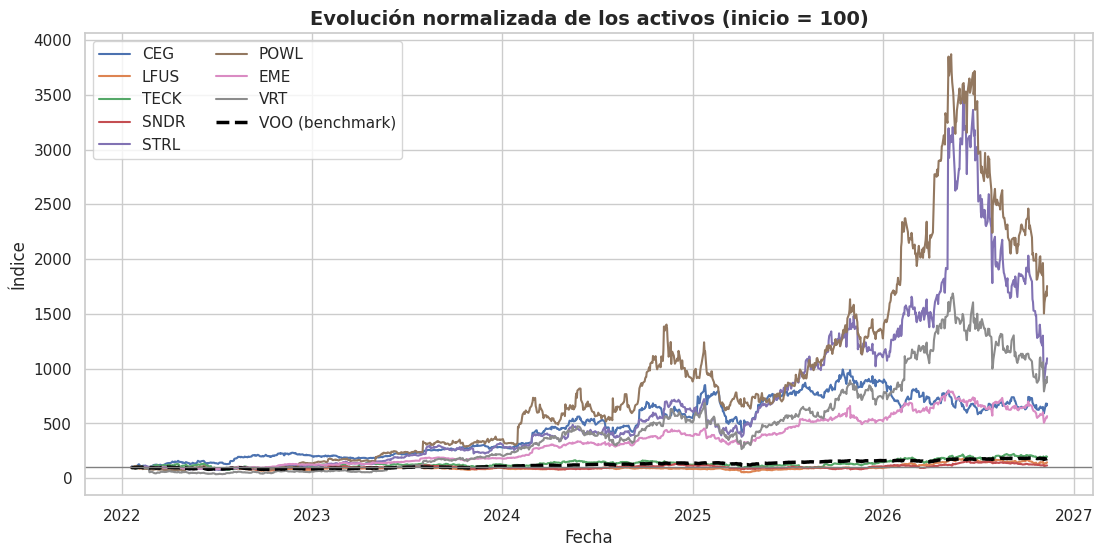

In [7]:
cierre_norm = cierre_total[activos] / cierre_total[activos].iloc[0] * 100
bench_norm = cierre_total[benchmark] / cierre_total[benchmark].iloc[0] * 100

fig, ax = plt.subplots(figsize=(13, 6))

for activo in activos:
    ax.plot(cierre_norm.index, cierre_norm[activo], linewidth=1.5, label=activo)

# El benchmark en negro y punteado para distinguirlo
ax.plot(bench_norm.index, bench_norm, color="black", linestyle="--", linewidth=2.5,
        label=f"{benchmark} (benchmark)")

ax.axhline(100, color="gray", linewidth=1)
ax.set_title("Evolución normalizada de los activos (inicio = 100)", fontsize=14, fontweight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Índice")
ax.legend(ncol=2)
plt.show()

### ✍️ 3.2 Preguntas

1. ¿Qué activo tuvo el mayor crecimiento en el período? ¿Cuál el menor?
2. ¿Cuántos activos le ganaron al benchmark?
3. ¿Hubo algún período en el que **todos** cayeran al mismo tiempo? ¿Coincide con algún evento de mercado que conozcas?

**Respuestas:**

# 4. Rendimientos de los activos y del portafolio

Recordemos las dos definiciones de la guía:

$$
R_t = \frac{P_t}{P_{t-1}} - 1 \qquad \text{(simple)}
\qquad\qquad
r_t = \ln\!\left(\frac{P_t}{P_{t-1}}\right) \qquad \text{(logarítmico)}
$$

### ¿Cómo se calcula el rendimiento del portafolio?

Hay un detalle importante: **los rendimientos simples se agregan entre activos** (promedio ponderado), mientras que **los logarítmicos se agregan en el tiempo** (suma). Por eso:

1. Calculamos el rendimiento **simple** del portafolio como un promedio ponderado:
$$
R_{p,t} = \sum_{i=1}^{n} w_i \, R_{i,t}
$$
2. Lo convertimos a logarítmico para el análisis estadístico:
$$
r_{p,t} = \ln(1 + R_{p,t})
$$

> 📌 Mantener los pesos $w_i$ constantes cada día supone que el portafolio se **rebalancea diariamente** para volver a los pesos objetivo. Es la simplificación habitual en un primer análisis.

### 🧩 4.1 Rendimientos de los activos

In [9]:
# Rendimientos simples (para agregar el portafolio)
rend_simple = (cierre_total/cierre_total.shift(1)-1).dropna()

# Rendimientos logarítmicos (para el análisis estadístico)
rendimientos = np.log(cierre_total/cierre_total.shift(1)).dropna()

rendimientos.head()

Ticker,CEG,LFUS,TECK,SNDR,STRL,POWL,EME,VRT,VOO
Date,,,,,,,,,
2022-01-20,0.0690,-0.0318,-0.0365,-0.0159,-0.0233,-0.0373,-0.0106,-0.0185,-0.0111
2022-01-21,0.0000,-0.0375,-0.0234,-0.0165,-0.0281,-0.0019,-0.0085,-0.0295,-0.0198
2022-01-24,-0.0501,0.0364,-0.0149,0.0237,0.0244,0.0856,0.0344,0.0268,0.0042
2022-01-25,-0.0213,-0.0430,0.0087,-0.0362,-0.0157,0.0656,-0.0348,-0.0329,-0.0122
2022-01-26,0.0311,-0.0103,0.0089,-0.0075,0.0011,-0.0094,-0.0051,-0.0277,-0.0023


### 🧩 4.2 Rendimiento del portafolio y del benchmark

Pista: el producto de un DataFrame por una Serie de pesos, seguido de `.sum(axis=1)`, da el promedio ponderado de cada fila. También puedes usar `rend_simple @ pesos`.

In [10]:
# optimizacion del CVaR, Portafolio con pesos eficientes
from scipy.optimize import minimize

def optimizar_pesos_cvar(retornos_sub, pesos_minimos=None, max_peso=0.15):
    """Minimiza el CVaR histórico al 95% de los activos seleccionados."""
    n = retornos_sub.shape[1]
    if n == 0:
        return pd.Series(dtype=float)
    if n == 1:
        return pd.Series([min(1.0, max_peso)], index=retornos_sub.columns)

    R = retornos_sub.fillna(0).values
    alpha = 0.05

    def objetivo_cvar(w):
        port_r = R @ w
        var_95 = np.percentile(port_r, alpha * 100)
        cola = port_r[port_r <= var_95]
        cvar = -np.mean(cola) if len(cola) > 0 else -var_95
        # Penalización suave por concentración para fomentar diversificación
        return cvar + 0.05 * np.sum(w ** 2)

    w0 = np.ones(n) / n
    bounds = [(0.02, max_peso) for _ in range(n)]
    constraints = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0}]

    res = minimize(objetivo_cvar, w0, method="SLSQP", bounds=bounds, constraints=constraints)
    if res.success:
        w_opt = res.x / np.sum(res.x)
    else:
        w_opt = w0
    return pd.Series(w_opt, index=retornos_sub.columns)

w_opt = optimizar_pesos_cvar(rendimientos[activos], max_peso=0.15)
print(w_opt)
pesos = w_opt
# Rendimiento simple diario del portafolio: promedio ponderado
rend_port_simple = rend_simple[activos].dot(pesos)

# Rendimiento logarítmico diario del portafolio
rend_port = rendimientos[activos].dot(pesos)
rend_port.name = "Portafolio"

# Rendimiento logarítmico diario del benchmark
rend_bench = rendimientos[benchmark].dropna()
rend_bench.name = benchmark

# Unimos todo en un solo DataFrame: activos + portafolio + benchmark
rend_todos = pd.concat([rendimientos[activos], rend_port, rend_bench], axis=1)
rend_todos.tail()

Ticker
CEG    0.1500
LFUS   0.1500
TECK   0.1500
SNDR   0.1500
STRL   0.0603
POWL   0.1500
EME    0.1500
VRT    0.0397
dtype: float64


,CEG,LFUS,TECK,SNDR,STRL,POWL,EME,VRT,Portafolio,VOO
Date,,,,,,,,,,
2026-11-05,-0.0250,-0.1037,-0.0732,-0.0541,-0.1492,-0.1348,-0.0712,-0.1511,-0.0843,-0.0447
2026-11-06,0.0421,0.0208,0.0091,-0.0153,0.0341,0.0625,0.0218,0.0341,0.0246,0.0030
2026-11-09,0.0995,0.0807,0.0673,0.0391,0.1395,0.0621,0.0705,0.0919,0.0750,0.0232
2026-11-10,-0.0306,-0.0059,-0.0285,0.0045,-0.0038,-0.0246,-0.0116,-0.0317,-0.0160,-0.0034
2026-11-11,0.0257,0.0367,0.0130,0.0041,0.0482,0.0541,0.0325,0.0614,0.0303,0.0128


### ✅ Verificación

In [11]:
assert len(rend_port) == len(rendimientos), "El portafolio debe tener un rendimiento por día."
assert not rend_port.isna().any(), "Hay NaN en el rendimiento del portafolio."
assert np.isclose(rend_port_simple.iloc[0], (rend_simple.iloc[0] * pesos).sum()), "Revisa el promedio ponderado."
print("✔ Rendimientos del portafolio correctos")

✔ Rendimientos del portafolio correctos


### 🧩 4.3 ¿Cuánto valdría la inversión?

Esta es **la primera gráfica que querrá ver un inversionista**. Si invertimos `monto_inicial` en el portafolio y la misma cantidad en el benchmark:

$$
V_t = V_0 \prod_{s=1}^{t} (1 + R_{p,s}) = V_0 \, \exp\!\left(\sum_{s=1}^{t} r_{p,s}\right)
$$

La segunda forma muestra la ventaja de los rendimientos logarítmicos: **para acumular en el tiempo basta con sumarlos**.

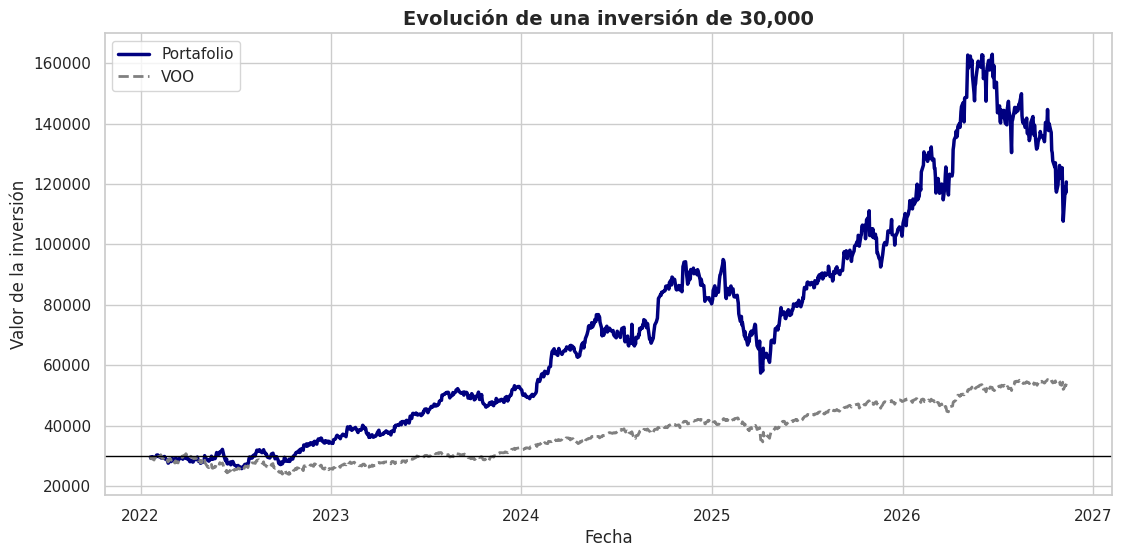

Valor final del portafolio :   120,657.38   (rendimiento total: 302.19%)
Valor final del benchmark  :    53,911.20   (rendimiento total: 79.70%)


In [12]:
valor_port = monto_inicial * np.exp(rend_port.cumsum())
valor_bench = monto_inicial * np.exp(rend_bench.cumsum())

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(valor_port.index, valor_port, linewidth=2.5, color="navy", label="Portafolio")
ax.plot(valor_bench.index, valor_bench, linewidth=2, color="gray", linestyle="--", label=benchmark)
ax.axhline(monto_inicial, color="black", linewidth=1)
ax.set_title(f"Evolución de una inversión de {monto_inicial:,.0f}", fontsize=14, fontweight="bold")
ax.set_xlabel("Fecha")
ax.set_ylabel("Valor de la inversión")
ax.legend()
plt.show()

print(f"Valor final del portafolio : {valor_port.iloc[-1]:>12,.2f}   "
      f"(rendimiento total: {valor_port.iloc[-1] / monto_inicial - 1:.2%})")
print(f"Valor final del benchmark  : {valor_bench.iloc[-1]:>12,.2f}   "
      f"(rendimiento total: {valor_bench.iloc[-1] / monto_inicial - 1:.2%})")

### ✍️ 4.4 💼 Mensaje para el inversionista

Completa la frase con tus resultados:

> *"Una inversión de 30000 en nuestro portafolio el 20-01-2022 se habría convertido en 140.408.78 el 11-11-2026, frente a 53.911.20 si se hubiera invertido en VOO."*

**Respuesta:**

# 5. Análisis exploratorio de los rendimientos

### 5.1 Rendimientos en el tiempo

Recuerda el problema del *spaghetti plot*: con series tan volátiles conviene usar **un panel por serie**.

🧩 Completa el número de filas de la figura y la serie que se grafica en cada panel.

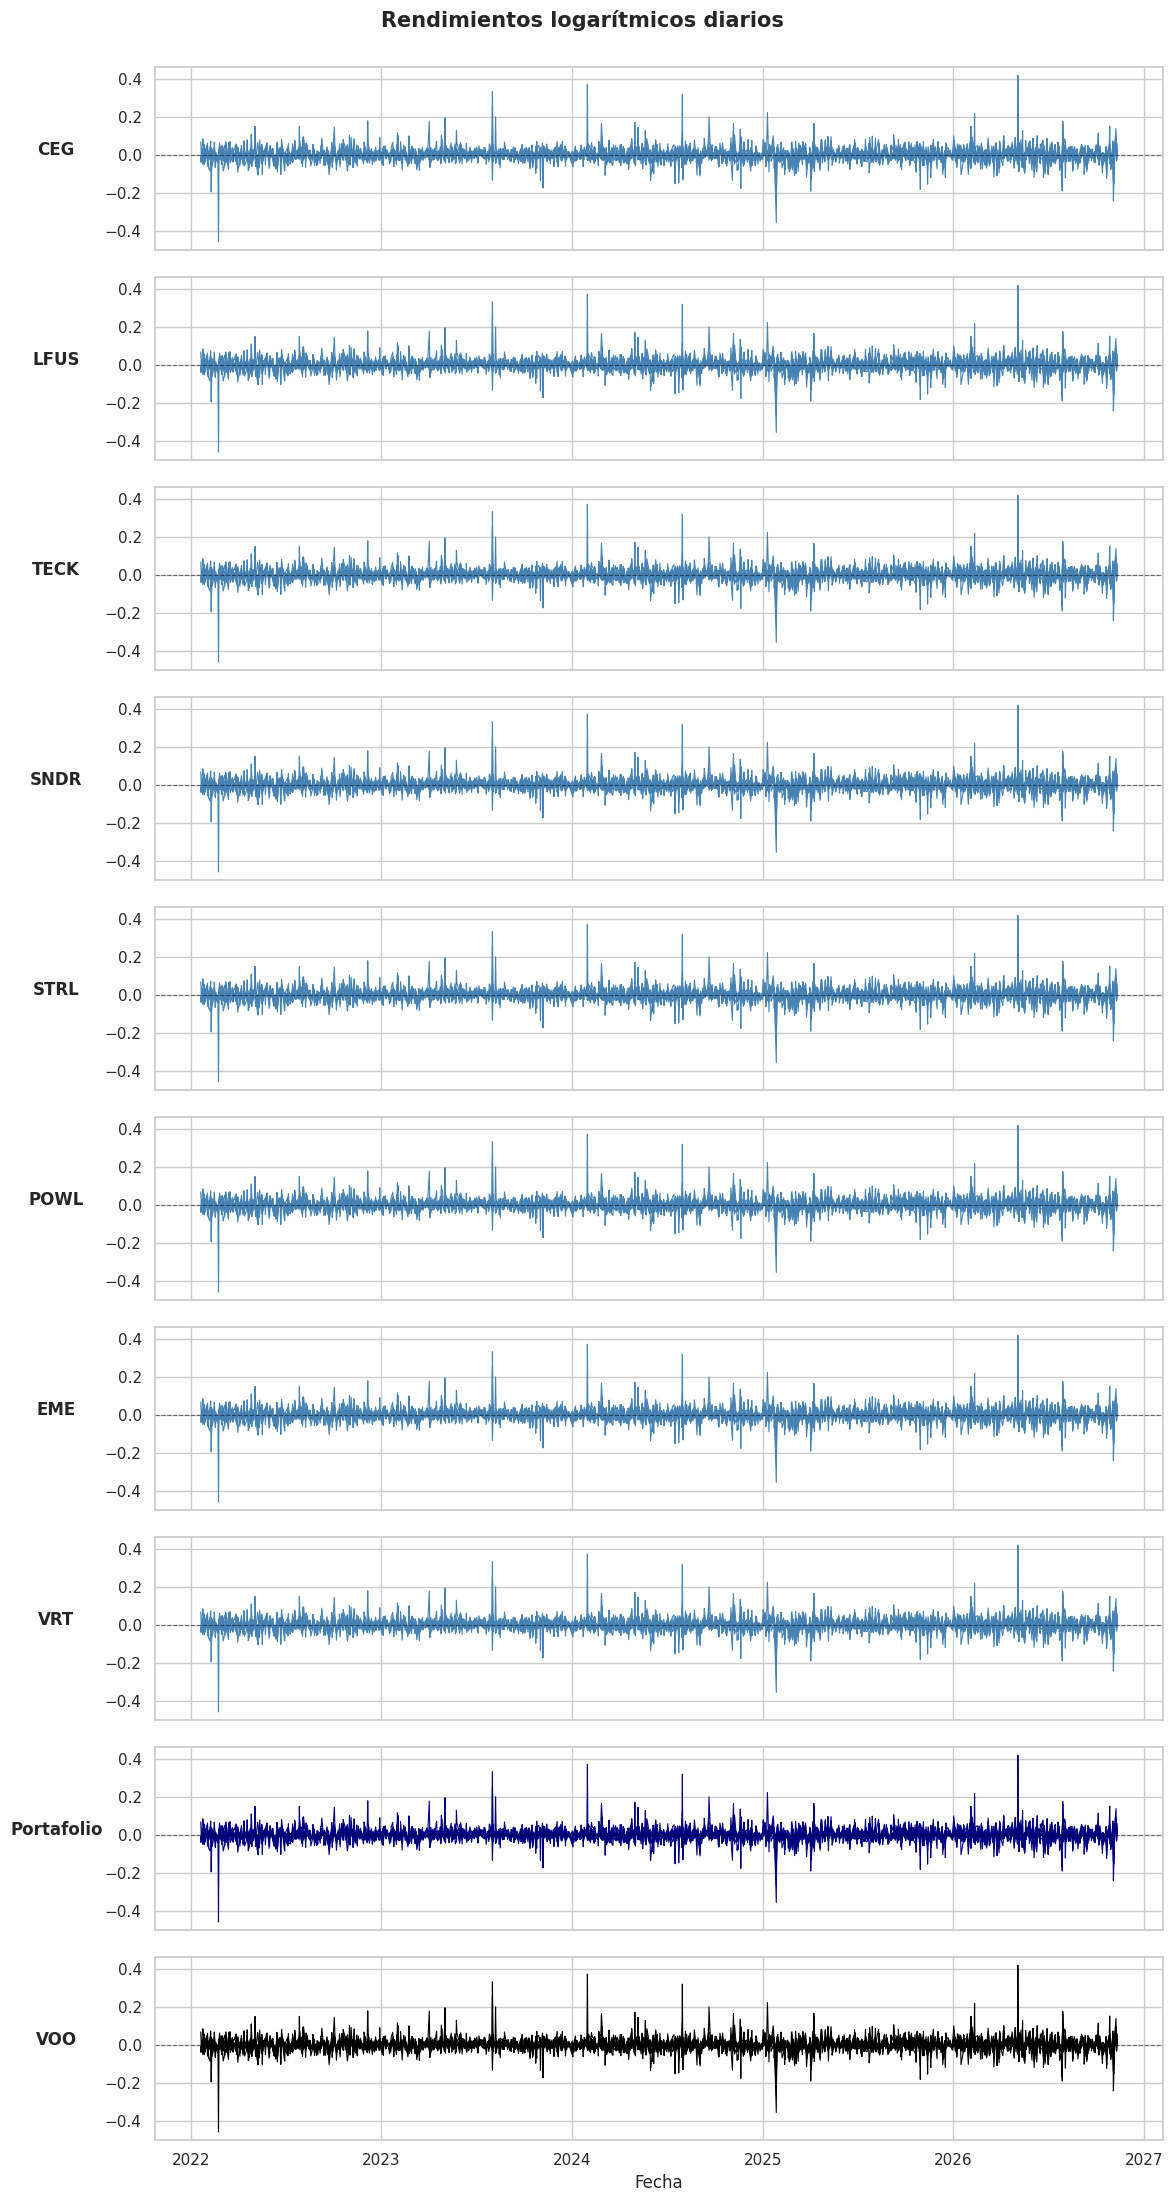

In [13]:
series = list(rend_todos.columns)   # activos + portafolio + benchmark

fig, axes = plt.subplots(nrows=rend_todos.shape[1], ncols=1, figsize=(12, 2.2 * len(series)), sharex=True)

for ax, nombre in zip(axes, series):
    color = "navy" if nombre == "Portafolio" else ("black" if nombre == benchmark else "steelblue")
    ax.plot(rend_todos.index, rend_todos, color=color, linewidth=0.8)
    ax.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.5)
    ax.set_ylabel(nombre, rotation=0, labelpad=35, fontweight="bold")

axes[-1].set_xlabel("Fecha")
fig.suptitle("Rendimientos logarítmicos diarios", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

### ✍️ Preguntas

1. Compara el panel del **portafolio** con el de los activos individuales. ¿Es más o menos "nervioso"? ¿Por qué?
2. ¿Identificas **agrupamiento de volatilidad** (períodos agitados seguidos de períodos agitados)?

**Respuestas:**

### 5.2 Distribución de los rendimientos

🧩 Completa el histograma con su curva KDE para cada serie.

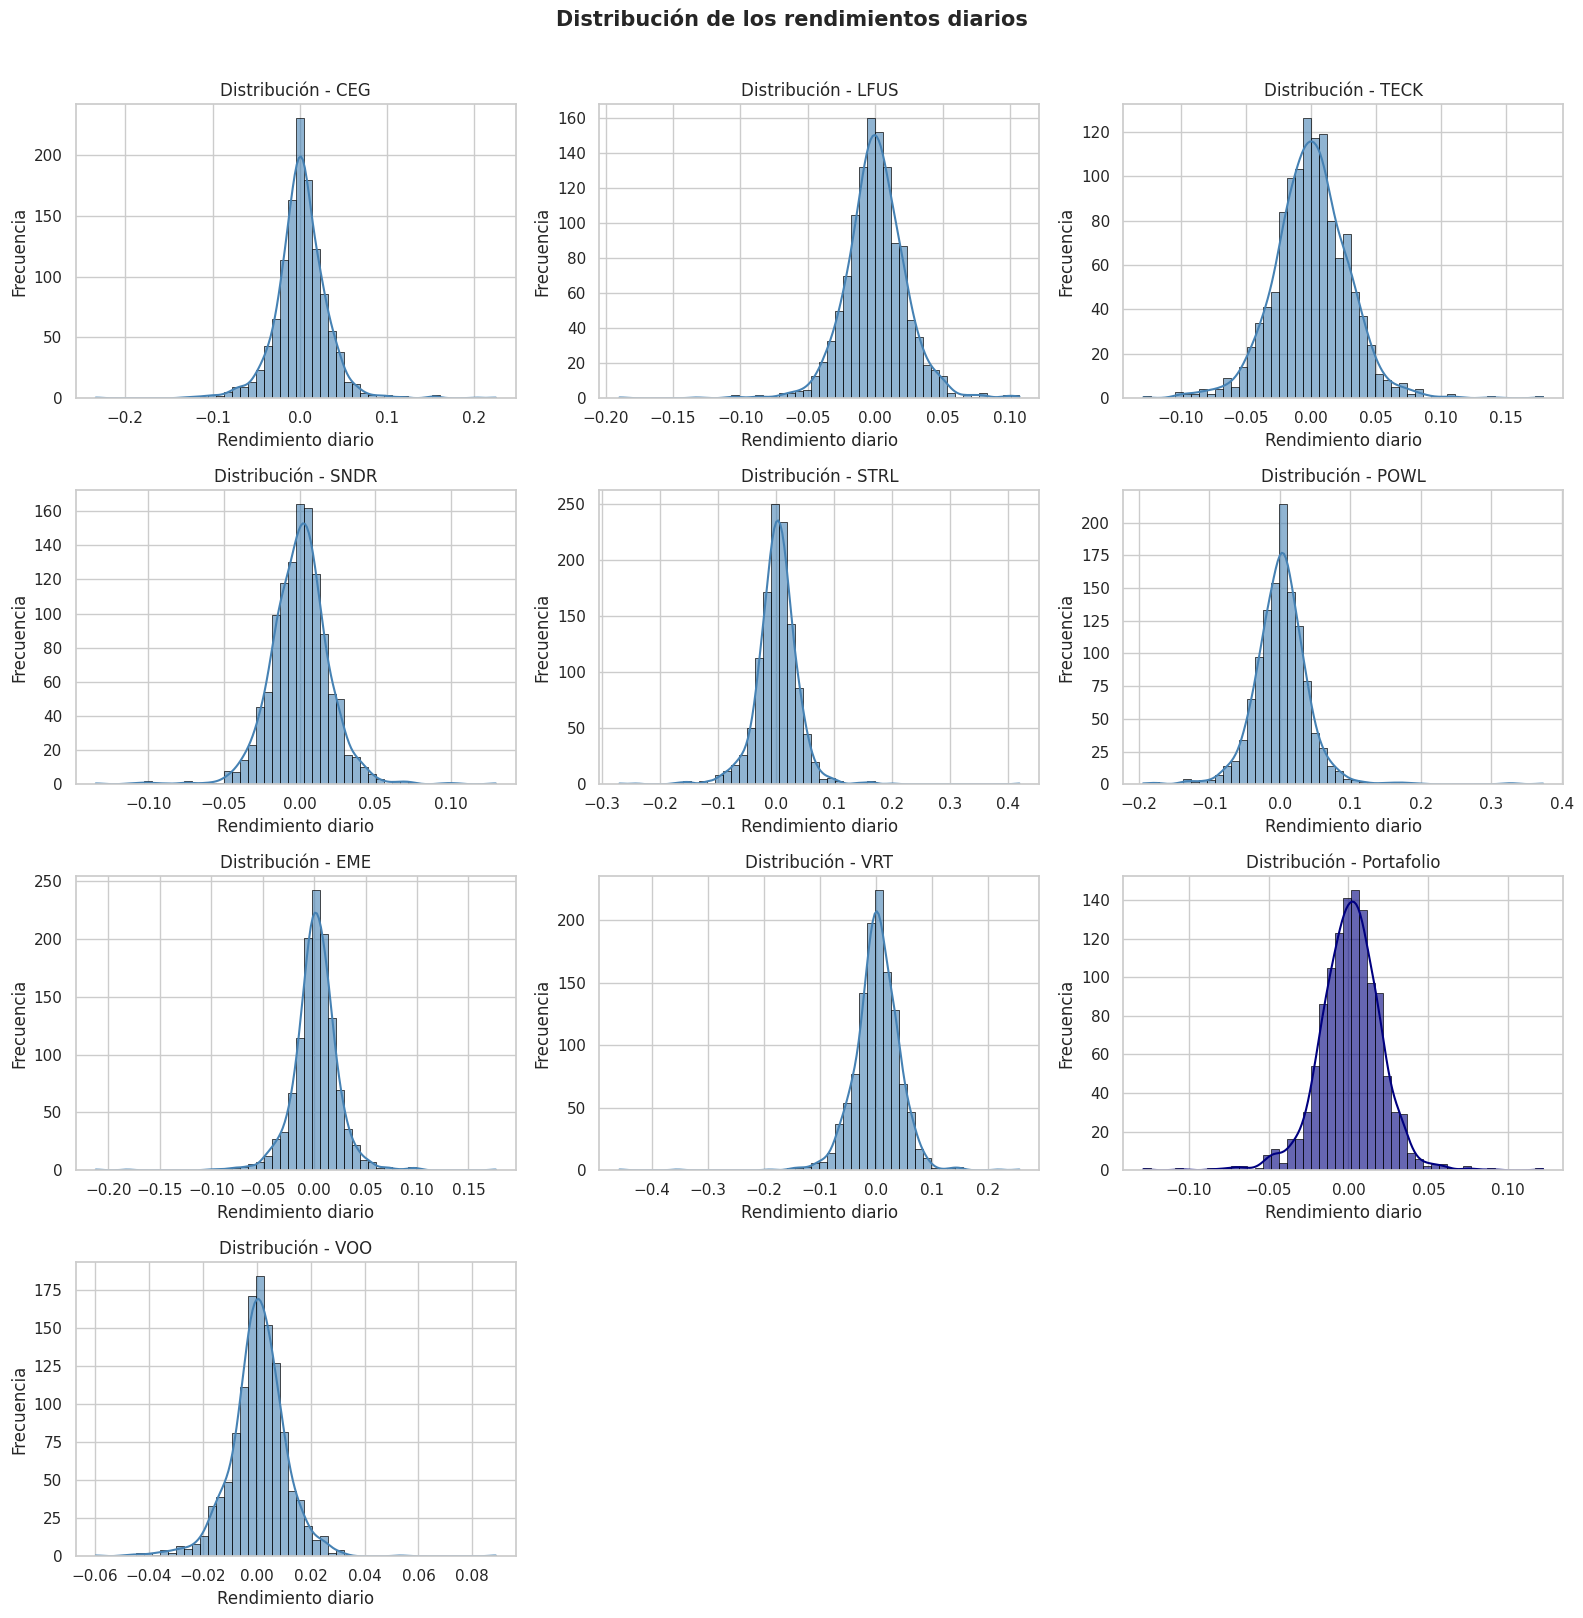

In [14]:
n_cols = 3
n_rows = math.ceil(len(series) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, nombre in enumerate(series):
    ax=axes[i]
    sns.histplot(
        data=rend_todos,
        x=nombre, #___
        bins=50,
        kde=True, #___
        ax=ax,  #axes[i],
        color="navy" if nombre == "Portafolio" else "steelblue",
        edgecolor="black",
        alpha=0.6
    )
    ax.set_title(f"Distribución - {nombre}")
    ax.set_xlabel("Rendimiento diario")
    ax.set_ylabel("Frecuencia")
    #axes[i].set_title(nombre, fontweight="bold")
    #axes[i].set_xlabel("Rendimiento diario")

# Ocultamos los paneles vacíos
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Distribución de los rendimientos diarios", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### 🧩 5.3 Comparar la dispersión con un boxplot

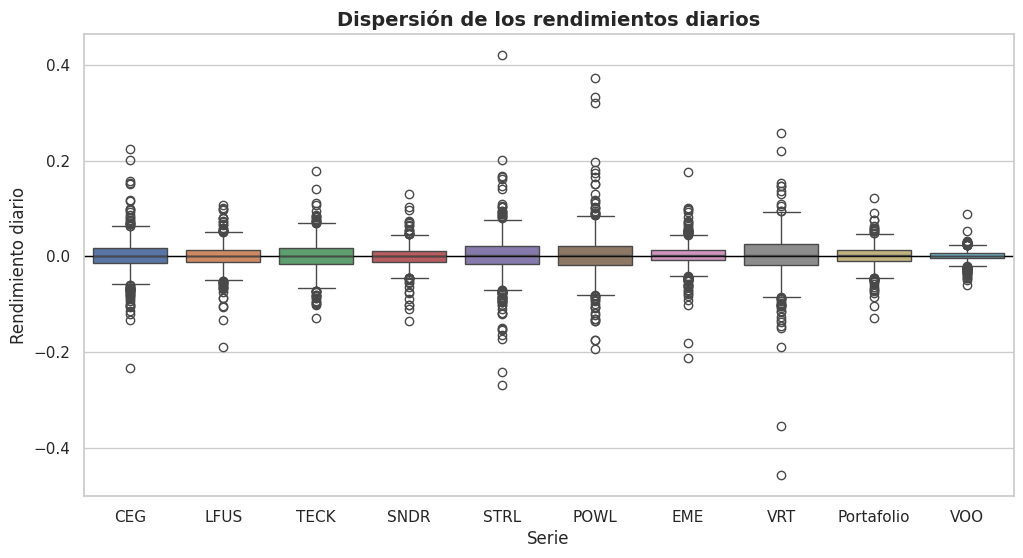

In [15]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=rend_todos)
plt.axhline(0, color="black", linewidth=1)
plt.title("Dispersión de los rendimientos diarios", fontsize=14, fontweight="bold")
plt.xlabel("Serie")
plt.ylabel("Rendimiento diario")
plt.show()

### ✍️ Preguntas

1. ¿Qué activo es el más disperso? ¿Cuál el menos?
2. ¿Dónde queda el portafolio frente a sus componentes?
3. ¿Qué activo presenta los valores atípicos más extremos?

**Respuestas:**

# 6. Estadísticas descriptivas y relación riesgo–rendimiento

Los inversionistas piensan en términos **anuales**. Con datos diarios y unos 252 días de negociación al año:

$$
\mu_{\text{anual}} \approx 252 \cdot \mu_{\text{diaria}}
\qquad\qquad
\sigma_{\text{anual}} \approx \sqrt{252} \cdot \sigma_{\text{diaria}}
$$

> 📌 La volatilidad crece con la **raíz** del tiempo, no proporcionalmente. Esta regla supone que los rendimientos diarios son independientes.

### 🧩 6.1 Tabla resumen

In [16]:
DIAS_ANIO = 252

resumen = pd.DataFrame({
    "Media diaria": rend_todos.mean(),
    "Mediana": rend_todos.median(),
    "Desv. estándar diaria": rend_todos.std(),
    "Mínimo": rend_todos.min(),
    "Máximo": rend_todos.max(),
})

resumen["Rend. anualizado"] = 252*resumen["Media diaria"]
resumen["Volatilidad anualizada"] = (252**(1/2))*resumen["Desv. estándar diaria"]

resumen.style.format("{:.2%}")

,Media diaria,Mediana,Desv. estándar diaria,Mínimo,Máximo,Rend. anualizado,Volatilidad anualizada
CEG,0.16%,0.15%,3.08%,-23.38%,22.44%,39.97%,48.95%
LFUS,0.03%,0.01%,2.34%,-18.97%,10.69%,7.84%,37.07%
TECK,0.06%,0.04%,2.88%,-12.88%,17.89%,14.12%,45.72%
SNDR,0.01%,0.07%,2.02%,-13.49%,12.97%,3.28%,32.02%
STRL,0.20%,0.29%,3.86%,-26.99%,42.02%,49.93%,61.30%
POWL,0.24%,0.23%,4.10%,-19.40%,37.35%,59.77%,65.02%
EME,0.14%,0.17%,2.29%,-21.22%,17.66%,36.21%,36.30%
VRT,0.18%,0.29%,4.27%,-45.79%,25.66%,46.44%,67.70%
Portafolio,0.12%,0.17%,1.97%,-12.85%,12.17%,29.03%,31.31%
VOO,0.05%,0.06%,1.08%,-5.97%,8.87%,12.23%,17.12%


### 🧩 6.2 Mapa riesgo–rendimiento

Cada punto es una serie: en el eje X su **riesgo** (volatilidad anualizada) y en el eje Y su **rendimiento** anualizado. Es una de las gráficas más útiles para el dashboard.

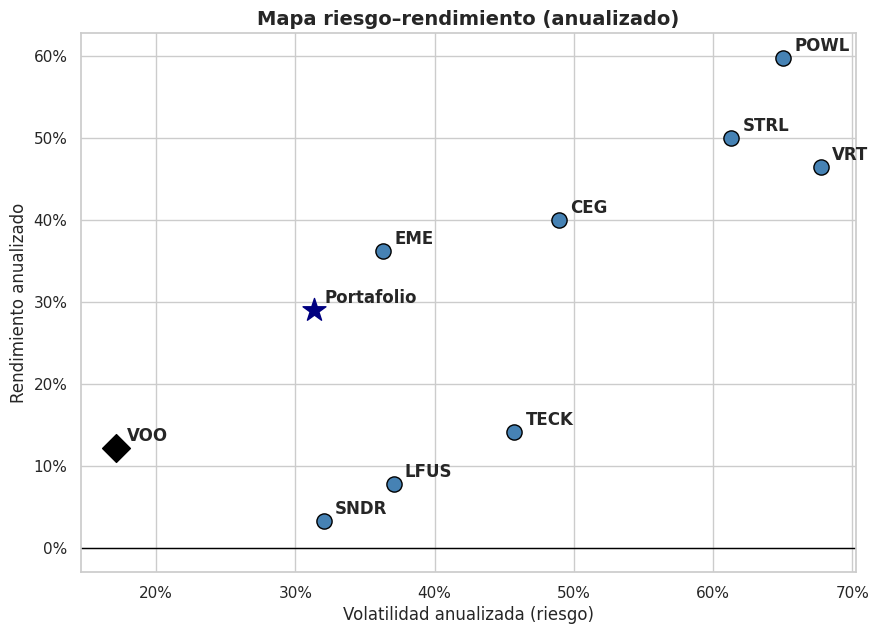

In [17]:
fig, ax = plt.subplots(figsize=(10, 7))

for nombre in resumen.index:
    x = resumen.loc[nombre,"Volatilidad anualizada" ]
    y = resumen.loc[nombre, "Rend. anualizado"]
    if nombre == "Portafolio":
        ax.scatter(x, y, s=300, color="navy", marker="*", zorder=3)
    elif nombre == benchmark:
        ax.scatter(x, y, s=200, color="black", marker="D", zorder=3)
    else:
        ax.scatter(x, y, s=120, color="steelblue", edgecolor="black", zorder=3)
    ax.annotate(nombre, (x, y), xytext=(8, 5), textcoords="offset points", fontweight="bold")

ax.axhline(0, color="black", linewidth=1)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Mapa riesgo–rendimiento (anualizado)", fontsize=14, fontweight="bold")
ax.set_xlabel("Volatilidad anualizada (riesgo)")
ax.set_ylabel("Rendimiento anualizado")
plt.show()

### ✍️ Preguntas

1. ¿Qué activos están "arriba y a la izquierda" (más rendimiento con menos riesgo)?
2. ¿El portafolio tiene **menos volatilidad que el promedio** de sus activos? ¿Por qué podría pasar eso?
3. 💼 ¿Qué activo le cuesta más riesgo al portafolio sin aportarle rendimiento?

**Respuestas:**

# 7. Correlación y diversificación

### 🧩 7.1 Matriz de correlación de los activos

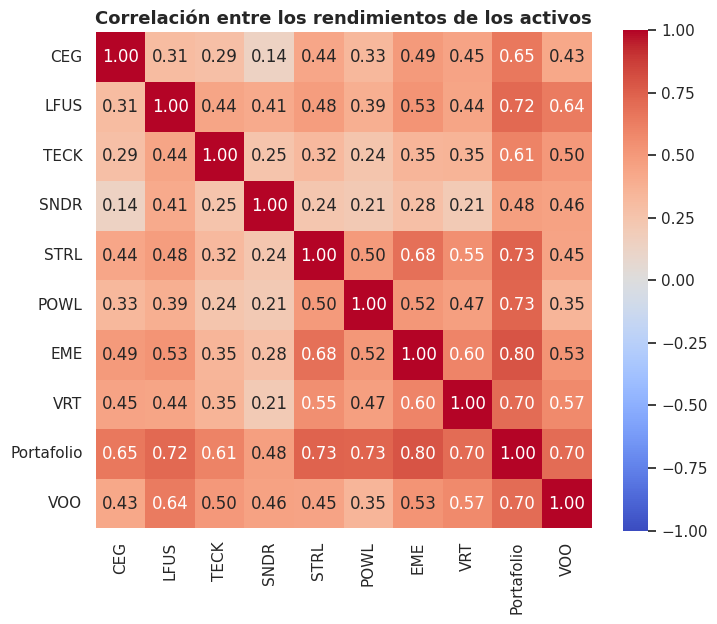

Correlación promedio entre activos: 0.47


In [18]:
correlacion = rend_todos.corr()

plt.figure(figsize=(8, 6.5))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True)
plt.title("Correlación entre los rendimientos de los activos", fontsize=13, fontweight="bold")
plt.show()

# Correlación promedio (sin la diagonal)
corr_promedio = correlacion.values[np.triu_indices_from(correlacion, k=1)].mean()
print(f"Correlación promedio entre activos: {corr_promedio:.2f}")

### 🧩 7.2 ¿Cuánto riesgo nos ahorra la diversificación?

Si todos los activos estuvieran **perfectamente correlacionados** ($\rho = 1$), la volatilidad del portafolio sería el promedio ponderado de las volatilidades:

$$
\sigma_{\text{sin diversificar}} = \sum_{i} w_i \, \sigma_i
$$

Como en la realidad $\rho < 1$, la volatilidad del portafolio es **menor**. Esa diferencia es el **beneficio de la diversificación**.

In [19]:
vol_activos = rendimientos.std() * np.sqrt(DIAS_ANIO)
#print(vol_activos[activos])
#print(pesos)

vol_sin_diversificar = sum(vol_activos[activos]*pesos) # np.dot(vol_activos[activos]*pesos) # daria igual
#print(vol_sin_diversificar)
#print(correlacion[:8][activos])
matriz_cov = correlacion[:8][activos] * np.outer(vol_activos[activos], vol_activos[activos]) # np.outer multiplica cada par de volatilidades (sigma_i * sigma_j)
varianza_portafolio = np.dot(pesos.T, np.dot(matriz_cov, pesos))
vol_portafolio = np.sqrt(varianza_portafolio)
beneficio_div = vol_sin_diversificar - vol_portafolio

print(f"Volatilidad si ρ = 1 (promedio ponderado): {vol_sin_diversificar:.2%}")
print(f"Volatilidad real del portafolio          : {vol_portafolio:.2%}")
print(f"Beneficio de la diversificación          : {beneficio_div:.2%} puntos de volatilidad "
      f"({beneficio_div / vol_sin_diversificar:.0%} menos riesgo)")

Volatilidad si ρ = 1 (promedio ponderado): 46.15%
Volatilidad real del portafolio          : 31.31%
Beneficio de la diversificación          : 14.83% puntos de volatilidad (32% menos riesgo)


### 🧩 7.3 Mira de cerca la pareja más correlacionada

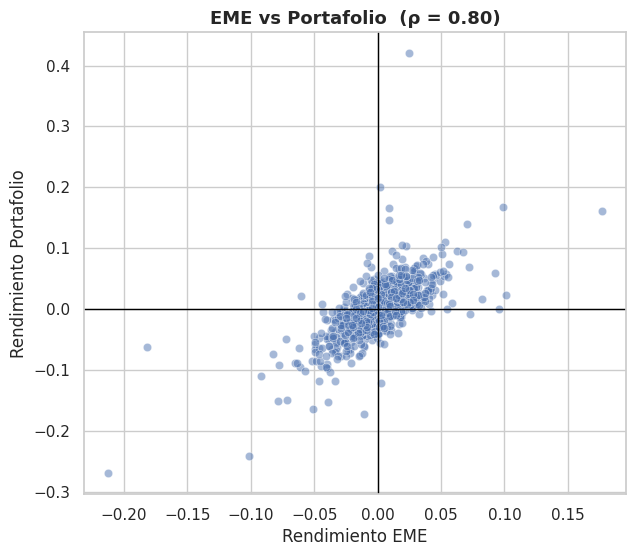

In [20]:
# Encontramos la pareja con la mayor correlación (fuera de la diagonal)
corr_sin_diag = correlacion.where(~np.eye(len(correlacion), dtype=bool))
a1, a2 = corr_sin_diag.stack().idxmax()

plt.figure(figsize=(7, 6))
sns.scatterplot(data=rendimientos, x="EME", y="STRL", alpha=0.5)
plt.axhline(0, color="black", linewidth=1)
plt.axvline(0, color="black", linewidth=1)
plt.title(f"{a1} vs {a2}  (ρ = {correlacion.loc[a1, a2]:.2f})", fontsize=13, fontweight="bold")
plt.xlabel(f"Rendimiento {a1}")
plt.ylabel(f"Rendimiento {a2}")
plt.show()

### ✍️ Preguntas

1. ¿Qué pareja de activos está más correlacionada? ¿Tiene sentido por su sector?
2. ¿Qué activo aporta más diversificación (menor correlación con los demás)?
3. 💼 Explica en dos líneas, sin tecnicismos, por qué el portafolio es menos riesgoso que sus activos por separado.

**Respuestas:**

# 8. Probabilidad empírica del portafolio

A partir de aquí el análisis se centra en el **portafolio completo**, que es lo que compra el inversionista.

$$
P(R \le x) \approx \frac{\text{días con rendimiento} \le x}{\text{total de días}}
$$

### 🧩 8.1 Probabilidades y cuantiles históricos

In [21]:
umbral_perdida = -0.02    # ejemplo: perder más del 2% en un día
umbral_ganancia = 0.02    # ejemplo: ganar más del 2% en un día

total_dias = len(rend_port)
print(rend_port)

#  Estimación de probabilidades basadas en frecuencia
# ¿Cuál es la probabilidad de tener un día con pérdida mayor al 2% (-0.02)?
dias_perdida_extrema = (rend_port < umbral_perdida).sum()
#total_dias = len(rendimientos[activos])
prob_perdida_emp = dias_perdida_extrema / total_dias

# ¿Cuál es la probabilidad de tener un día con ganancia mayor al 2% (0.02)?
dias_ganancia_extrema = (rend_port > umbral_ganancia).sum()
prob_ganancia_emp = dias_ganancia_extrema / total_dias

# Cuantiles empíricos
q05_emp = rend_port.quantile(0.05)
q01_emp = rend_port.quantile(0.01)
intervalo_95_emp = (rend_port.quantile(0.025), rend_port.quantile(0.975))

print(f"Días analizados: {total_dias}\n")
print(f"P(R <= {umbral_perdida:.0%})  = {prob_perdida_emp:.2%}  "
      f"-> aprox. {prob_perdida_emp * DIAS_ANIO:.0f} días al año")
print(f"P(R >  {umbral_ganancia:.0%})  = {prob_ganancia_emp:.2%}  "
      f"-> aprox. {prob_ganancia_emp * DIAS_ANIO:.0f} días al año\n")
print(f"Cuantil 5%  (VaR histórico 95%): {q05_emp:.2%}")
print(f"Cuantil 1%  (VaR histórico 99%): {q01_emp:.2%}")
print(f"Intervalo empírico del 95%      : [{intervalo_95_emp[0]:.2%}, {intervalo_95_emp[1]:.2%}]")

Date
2022-01-20   -0.0116
2022-01-21   -0.0160
2022-01-24    0.0198
2022-01-25   -0.0114
2022-01-26    0.0001
               ...  
2026-11-05   -0.0843
2026-11-06    0.0246
2026-11-09    0.0750
2026-11-10   -0.0160
2026-11-11    0.0303
Name: Portafolio, Length: 1208, dtype: float64
Días analizados: 1208

P(R <= -2%)  = 10.60%  -> aprox. 27 días al año
P(R >  2%)  = 13.33%  -> aprox. 34 días al año

Cuantil 5%  (VaR histórico 95%): -2.95%
Cuantil 1%  (VaR histórico 99%): -4.97%
Intervalo empírico del 95%      : [-4.18%, 3.62%]


### ✍️ 8.2 💼 Traduce a lenguaje de inversionista

> *"Según la historia del período, en ____ de cada 100 días el portafolio perdió más del ____. En el 5% de los peores días, la pérdida fue de al menos ____."*

**Respuesta:**

# 9. ¿Son normales los rendimientos del portafolio?

Muchos modelos (Markowitz, VaR paramétrico, Black-Scholes) suponen que los rendimientos son normales:

$$
r_p \sim N(\mu, \sigma^2),
\qquad
F(x) = P(r_p \le x) = \int_{-\infty}^{x} f(t)\,dt,
\qquad
x_q = F^{-1}(q)
$$

Recuerda las funciones de `scipy.stats.norm`:

| Función | Va de → a | Uso |
|---|---|---|
| `norm.pdf(x, loc=μ, scale=σ)` | valor → densidad | dibujar la campana |
| `norm.cdf(x, loc=μ, scale=σ)` | valor → probabilidad | $P(X \le x)$ |
| `norm.sf(x, loc=μ, scale=σ)` | valor → probabilidad | $P(X > x)$ |
| `norm.ppf(q, loc=μ, scale=σ)` | probabilidad → valor | cuantiles, VaR |

> ⚠️ `scale` es la **desviación estándar**, no la varianza.

### 🧩 9.1 Estima los parámetros y superpone la normal al histograma

μ diaria = 0.00115   σ diaria = 0.01972


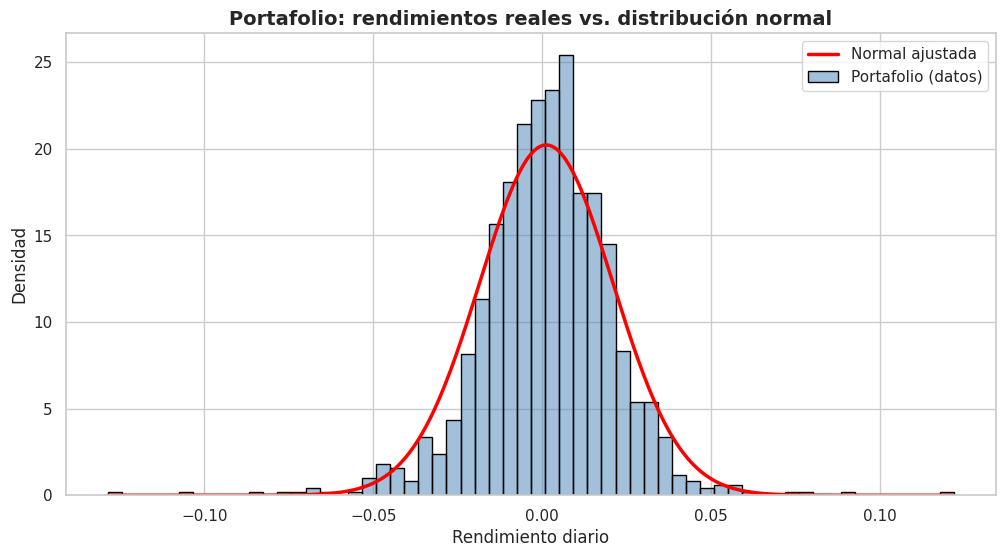

In [22]:
mu_p = rend_port.mean()
sigma_p = rend_port.std()

print(f"μ diaria = {mu_p:.5f}   σ diaria = {sigma_p:.5f}")

fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(rend_port, bins=60, stat="density", color="steelblue", alpha=0.5,
             edgecolor="black", label="Portafolio (datos)", ax=ax)

x = np.linspace(rend_port.min(), rend_port.max(), 500)
ax.plot(x, norm.pdf(x, loc=mu_p, scale=sigma_p), color="red", linewidth=2.5,
        label="Normal ajustada")

ax.set_title("Portafolio: rendimientos reales vs. distribución normal", fontsize=14, fontweight="bold")
ax.set_xlabel("Rendimiento diario")
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

### 9.2 La probabilidad como área

Esta función ya está lista (es la misma de la guía). Solo ejecútala.

In [23]:
def graficar_area_normal(mu=0, sigma=1, a=None, b=None, ax=None):
    # Grafica la densidad N(mu, sigma) y sombrea P(a <= X <= b).
    # a=None -> cola izquierda | b=None -> cola derecha
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5))
    x = np.linspace(mu - 4 * sigma, mu + 4 * sigma, 1000)
    y = norm.pdf(x, loc=mu, scale=sigma)
    ax.plot(x, y, color="navy", linewidth=2, label=f"N(μ={mu:.4g}, σ={sigma:.4g})")
    li = -np.inf if a is None else a
    ls = np.inf if b is None else b
    ax.fill_between(x, y, where=(x >= li) & (x <= ls), color="tomato", alpha=0.5)
    prob = norm.cdf(ls, loc=mu, scale=sigma) - norm.cdf(li, loc=mu, scale=sigma)
    if a is None:
        etiqueta = f"P(X ≤ {b:g}) = {prob:.4f}"
    elif b is None:
        etiqueta = f"P(X ≥ {a:g}) = {prob:.4f}"
    else:
        etiqueta = f"P({a:g} ≤ X ≤ {b:g}) = {prob:.4f}"
    for lim in [a, b]:
        if lim is not None:
            ax.axvline(lim, color="tomato", linestyle="--", linewidth=1.5)
    ax.set_title(etiqueta, fontsize=13, fontweight="bold")
    ax.set_ylim(bottom=0)
    ax.legend(loc="upper right")
    return prob

### 🧩 9.3 Probabilidad de pérdida según la normal

Sombrea la probabilidad de que el portafolio pierda más que `umbral_perdida` y compárala con la empírica de la sección 8.

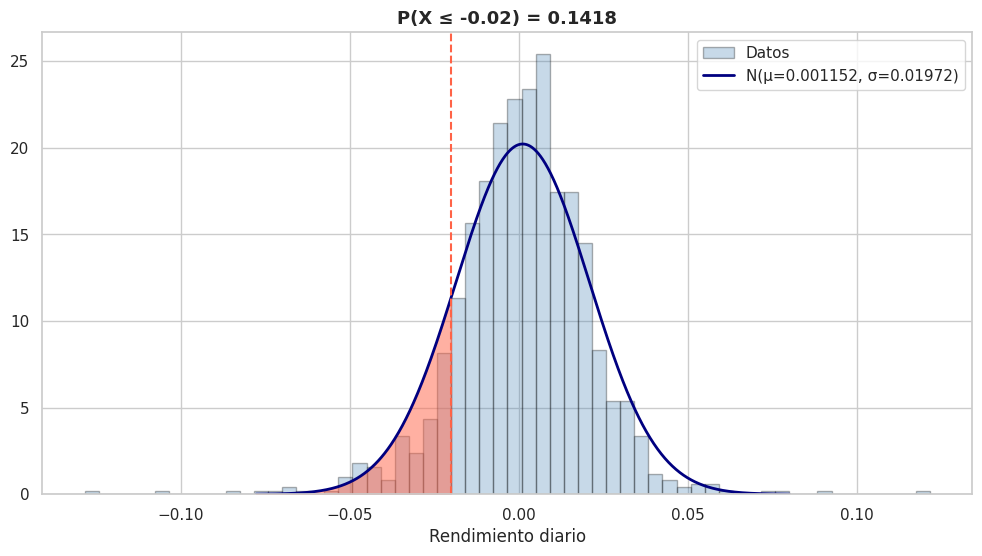

P(R <= -2%) normal   : 14.18%
P(R <= -2%) empírica : 10.60%


In [24]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(rend_port, bins=60, density=True, color="steelblue", alpha=0.3,
        edgecolor="black", label="Datos")

prob_perdida_norm = graficar_area_normal(mu=mu_p, sigma=sigma_p, b=-0.02, ax=ax)
ax.set_xlabel("Rendimiento diario")
plt.show()

print(f"P(R <= {umbral_perdida:.0%}) normal   : {prob_perdida_norm:.2%}")
print(f"P(R <= {umbral_perdida:.0%}) empírica : {prob_perdida_emp:.2%}")

### 🧩 9.4 Normal vs. historia: probabilidades y cuantiles

In [25]:
# Probabilidades en la cola izquierda
umbrales = [-0.01, -0.02, -0.03, -0.04]
tabla_prob = pd.DataFrame({
    "Umbral": umbrales,
    "Prob. normal": [norm.cdf(u, loc=mu_p, scale=sigma_p) for u in umbrales],
    "Prob. empírica": [(rend_port <= u).mean() for u in umbrales],
})
tabla_prob["Empírica / Normal"] = tabla_prob["Prob. empírica"] / tabla_prob["Prob. normal"]

# Cuantiles (VaR paramétrico vs. histórico)
niveles = [0.01, 0.025, 0.05]
tabla_cuant = pd.DataFrame({
    "Nivel": niveles,
    "Cuantil normal": norm.ppf(niveles, loc=mu_p, scale=sigma_p),
    "Cuantil empírico": rend_port.quantile(niveles).values
})

display(tabla_prob.style.format({"Umbral": "{:.0%}", "Prob. normal": "{:.2%}",
                                 "Prob. empírica": "{:.2%}", "Empírica / Normal": "{:.2f}"}))
display(tabla_cuant.style.format({"Nivel": "{:.1%}", "Cuantil normal": "{:.2%}",
                                  "Cuantil empírico": "{:.2%}"}))

,Umbral,Prob. normal,Prob. empírica,Empírica / Normal
0,-1%,28.59%,25.17%,0.88
1,-2%,14.18%,10.60%,0.75
2,-3%,5.71%,4.88%,0.85
3,-4%,1.85%,2.65%,1.43


,Nivel,Cuantil normal,Cuantil empírico
0,1.0%,-4.47%,-4.97%
1,2.5%,-3.75%,-4.18%
2,5.0%,-3.13%,-2.95%


### 🧩 9.5 Forma de la distribución: asimetría, curtosis y prueba de normalidad

- **Asimetría** < 0: las caídas extremas pesan más que las subidas extremas.
- **Exceso de curtosis** > 0: colas pesadas, con más días extremos que en la normal.
- **Jarque-Bera**: $H_0$ = los datos son normales. Si el p-valor es < 0.05, se rechaza la normalidad.
- **Gráfico Q-Q**: si los puntos se separan de la recta en los extremos, hay colas pesadas.

Asimetría          : -0.316
Exceso de curtosis : 4.364
Jarque-Bera        : estadístico = 978.61, p-valor = 3.152e-213


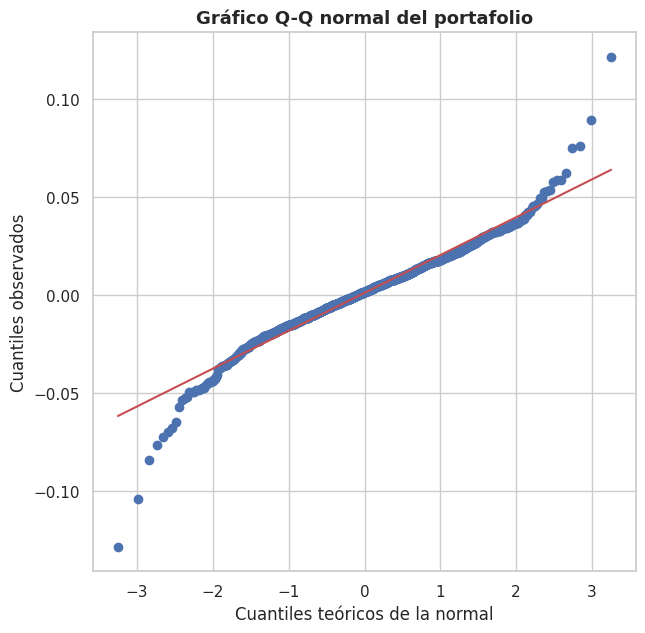

In [26]:
asimetria_p = stats.skew(rend_port)
curtosis_p = stats.kurtosis(rend_port)       # exceso de curtosis (normal = 0)
jb_p = stats.jarque_bera(rend_port)

print(f"Asimetría          : {asimetria_p:.3f}")
print(f"Exceso de curtosis : {curtosis_p:.3f}")
print(f"Jarque-Bera        : estadístico = {jb_p.statistic:.2f}, p-valor = {jb_p.pvalue:.4g}")

fig, ax = plt.subplots(figsize=(7, 7))
stats.probplot(rend_port, dist="norm", plot=ax)
ax.set_title("Gráfico Q-Q normal del portafolio", fontsize=13, fontweight="bold")
ax.set_xlabel("Cuantiles teóricos de la normal")
ax.set_ylabel("Cuantiles observados")
plt.show()

### ✍️ 9.6 Preguntas

1. ¿Se puede suponer que los rendimientos del portafolio son normales? Justifica con **al menos dos** evidencias (gráfica, asimetría y curtosis, Jarque-Bera, Q-Q, tabla de probabilidades).
2. En la cola izquierda, ¿la normal **subestima** o **sobrestima** la probabilidad de pérdidas grandes? ¿Qué consecuencia tendría eso para un inversionista?
3. ¿Qué VaR al 99% le reportarías a un inversionista conservador: el normal o el histórico? ¿Por qué?

**Respuestas:**

# 10. El riesgo en dinero: Valor en Riesgo (VaR)

Al inversionista le dice poco que "el cuantil 5% es −1.8%". Le dice mucho más:

> *"Con un 95% de confianza, en un día normal el portafolio no debería perder más de **USD 180**."*

Como trabajamos con rendimientos logarítmicos, la pérdida en dinero asociada a un cuantil $r_q$ es:

$$
\text{VaR}_{\$} = V \cdot \left(1 - e^{\,r_q}\right)
$$

donde $V$ es el valor actual del portafolio.

### 🧩 10.1 Calcula el VaR diario en dinero

In [27]:
valor_actual = valor_port.iloc[-1]

def var_dinero(cuantil_log, valor):
    # Pérdida monetaria asociada a un rendimiento logarítmico (positiva = pérdida)
    return - cuantil_log*valor

var_tabla = pd.DataFrame({
    "VaR normal (%)": [norm.ppf(0.05, mu_p, sigma_p), norm.ppf(0.01, mu_p, sigma_p)],
    "VaR histórico (%)": [np.percentile(rend_port, 0.05), np.percentile(rend_port, 0.01)],
}, index=["95%", "99%"])


print(var_tabla["VaR normal (%)"])
print(var_tabla["VaR histórico (%)"])

var_tabla["VaR normal ($)"] = var_dinero(var_tabla["VaR normal (%)"], valor_actual)
var_tabla["VaR histórico ($)"] = var_dinero(var_tabla["VaR histórico (%)"], valor_actual)

print(f"Valor actual del portafolio: {valor_actual:,.2f}\n")
var_tabla.style.format({"VaR normal (%)": "{:.2%}", "VaR histórico (%)": "{:.2%}",
                        "VaR normal ($)": "{:,.2f}", "VaR histórico ($)": "{:,.2f}"})

95%   -0.0313
99%   -0.0447
Name: VaR normal (%), dtype: float64
95%   -0.1138
99%   -0.1255
Name: VaR histórico (%), dtype: float64
Valor actual del portafolio: 120,657.38



,VaR normal (%),VaR histórico (%),VaR normal ($),VaR histórico ($)
95%,-3.13%,-11.38%,"3,775.61","13,736.59"
99%,-4.47%,-12.55%,"5,397.51","15,148.11"


### ✍️ 10.2 💼 Frase para el dashboard

> *"Con un ____% de confianza, la pérdida del portafolio en un día no debería superar ____ (____% de su valor). Sin embargo, este cálculo se basa en datos históricos y ____."*

**Respuesta:**

# 11. Ficha técnica del portafolio

Reunimos en una sola tabla los indicadores clave, comparados contra el benchmark. Esta tabla será el corazón del dashboard.

Dos indicadores nuevos y sencillos:

- **Razón de Sharpe**: cuánto rendimiento extra se obtiene por cada unidad de riesgo:
$$
\text{Sharpe} = \frac{\mu_{\text{anual}} - r_f}{\sigma_{\text{anual}}}
$$
donde $r_f$ es la tasa libre de riesgo (por ejemplo, la tasa de los bonos del Tesoro de EE. UU. a corto plazo).

- **Máxima caída (*maximum drawdown*)**: la peor caída desde un máximo previo hasta un mínimo posterior. Responde a *"¿cuánto es lo máximo que habría perdido si hubiera entrado en el peor momento?"*
$$
\text{Drawdown}_t = \frac{V_t}{\max_{s \le t} V_s} - 1
$$

### 🧩 11.1 Construye la ficha

In [28]:
tasa_libre_riesgo = 0.0456   # anual; consulta una tasa de referencia actual Investing.com: El rendimiento del bono a 1 año (US1YT) cotiza cerca del 4,56%.

peak= valor_port.cummax()

def max_drawdown(valor):
    # Peor caída desde un máximo previo (número negativo)
    maximo_previo = valor.cummax()
    drawdown = valor / maximo_previo - 1
    return drawdown.min()

def ficha(r, valor):
    # Indicadores clave a partir de rendimientos log diarios y la serie de valor
    mu_a = r.mean() * DIAS_ANIO
    sigma_a = r.std() * np.sqrt(DIAS_ANIO)
    print("ss",sigma_a)
    return {
        "Rendimiento total": valor.iloc[-1] / valor.iloc[0] - 1,
        "Rendimiento anualizado": mu_a,
        "Volatilidad anualizada": sigma_a,
        "Sharpe": (mu_p-tasa_libre_riesgo)/sigma_p,
        "Máxima caída": ((valor_port-peak)/peak).min() ,
        "VaR 95% diario (histórico)": r.quantile(0.05),
        "Peor día": r.min(),
        "Mejor día": r.max(),
        "Asimetría": stats.skew(r),
        "Exceso de curtosis": stats.kurtosis(r),
    }

# La serie de valor arranca en el primer día con rendimiento; anteponemos el monto inicial
valor_port_c = pd.concat([pd.Series([monto_inicial], index=[cierre.index[0]]), valor_port])
valor_bench_c = pd.concat([pd.Series([monto_inicial], index=[cierre.index[0]]), valor_bench])

#print(((rend_port.mean()*DIAS_ANIO)-tasa_libre_riesgo)/(rend_port.std()*np.sqrt(DIAS_ANIO)))
#print(rend_port.std()*np.sqrt(DIAS_ANIO))
#print(valor_port)

ficha_tecnica = pd.DataFrame({
    "Portafolio": ficha(rend_port, valor_port_c ),
    benchmark: ficha(rend_bench, valor_bench_c ),
})

formatos = {k: "{:.2%}" for k in ficha_tecnica.index}
formatos.update({"Sharpe": "{:.2f}", "Asimetría": "{:.2f}", "Exceso de curtosis": "{:.2f}"})
ficha_tecnica.apply(lambda fila: fila.map(lambda v: formatos[fila.name].format(v)), axis=1)

ss 0.31311828201364256
ss 0.17117619682713245


,Portafolio,VOO
Rendimiento total,302.19%,79.70%
Rendimiento anualizado,29.03%,12.23%
Volatilidad anualizada,31.31%,17.12%
Sharpe,-2.25,-2.25
Máxima caída,-39.55%,-39.55%
VaR 95% diario (histórico),-2.95%,-1.65%
Peor día,-12.85%,-5.97%
Mejor día,12.17%,8.87%
Asimetría,-0.32,-0.04
Exceso de curtosis,4.36,6.06


### 🧩 11.2 Gráfica de *drawdown*

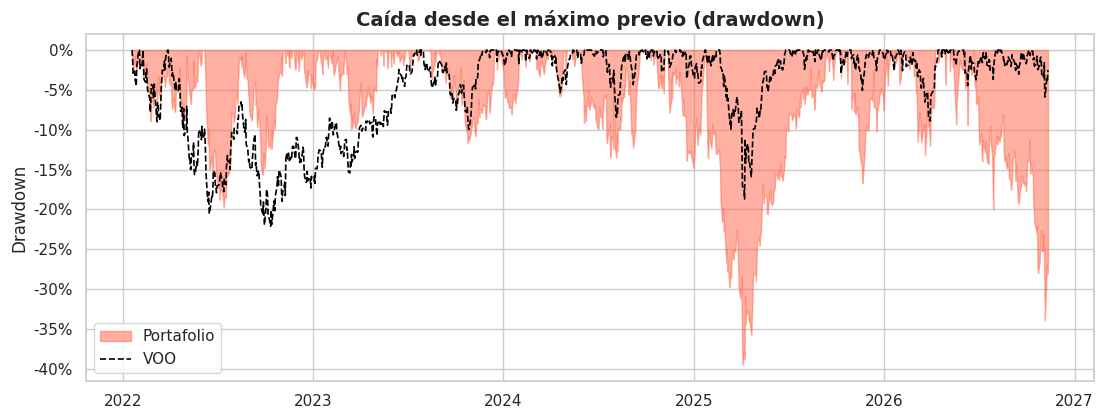

In [29]:
dd_port =  (valor_port_c   / valor_port_c.cummax() - 1)#.min()
dd_bench = (valor_bench_c / valor_bench_c.cummax() - 1)#.min()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(dd_port.index, dd_port, 0, color="tomato", alpha=0.5, label="Portafolio")
ax.plot(dd_bench.index, dd_bench, color="black", linestyle="--", linewidth=1.2, label=benchmark)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Caída desde el máximo previo (drawdown)", fontsize=14, fontweight="bold")
ax.set_ylabel("Drawdown")
ax.legend(loc="lower left")
plt.show()

### ✍️ 11.3 Preguntas

1. ¿El portafolio le ganó al benchmark en rendimiento? ¿Y en rendimiento **ajustado por riesgo** (Sharpe)?
2. ¿Cuál fue la máxima caída y cuándo ocurrió? ¿Cuánto tiempo tardó en recuperarse?
3. 💼 Si tuvieras que mostrar **solo tres** indicadores de la ficha en el dashboard, ¿cuáles elegirías y por qué?

**Respuestas:**

# 12. Borrador del dashboard

Un dashboard **no es una colección de todos los gráficos**: es una selección de los que responden las preguntas del inversionista:

| Pregunta del inversionista | Panel |
|---|---|
| ¿Qué tengo? | Composición del portafolio |
| ¿Cuánto he ganado? | Valor de la inversión vs. benchmark |
| ¿Cuánto riesgo asumo? | Mapa riesgo–rendimiento |
| ¿Estoy diversificado? | Matriz de correlación |
| ¿Cuánto puedo perder en un mal día? | Distribución con VaR |
| ¿Qué tan mal se puso en el peor momento? | Drawdown |

Vamos a armar un borrador estático en una sola figura. En el proyecto lo convertirán en un dashboard completo.

### 🧩 12.1 Completa los paneles que faltan

0.465741542779563


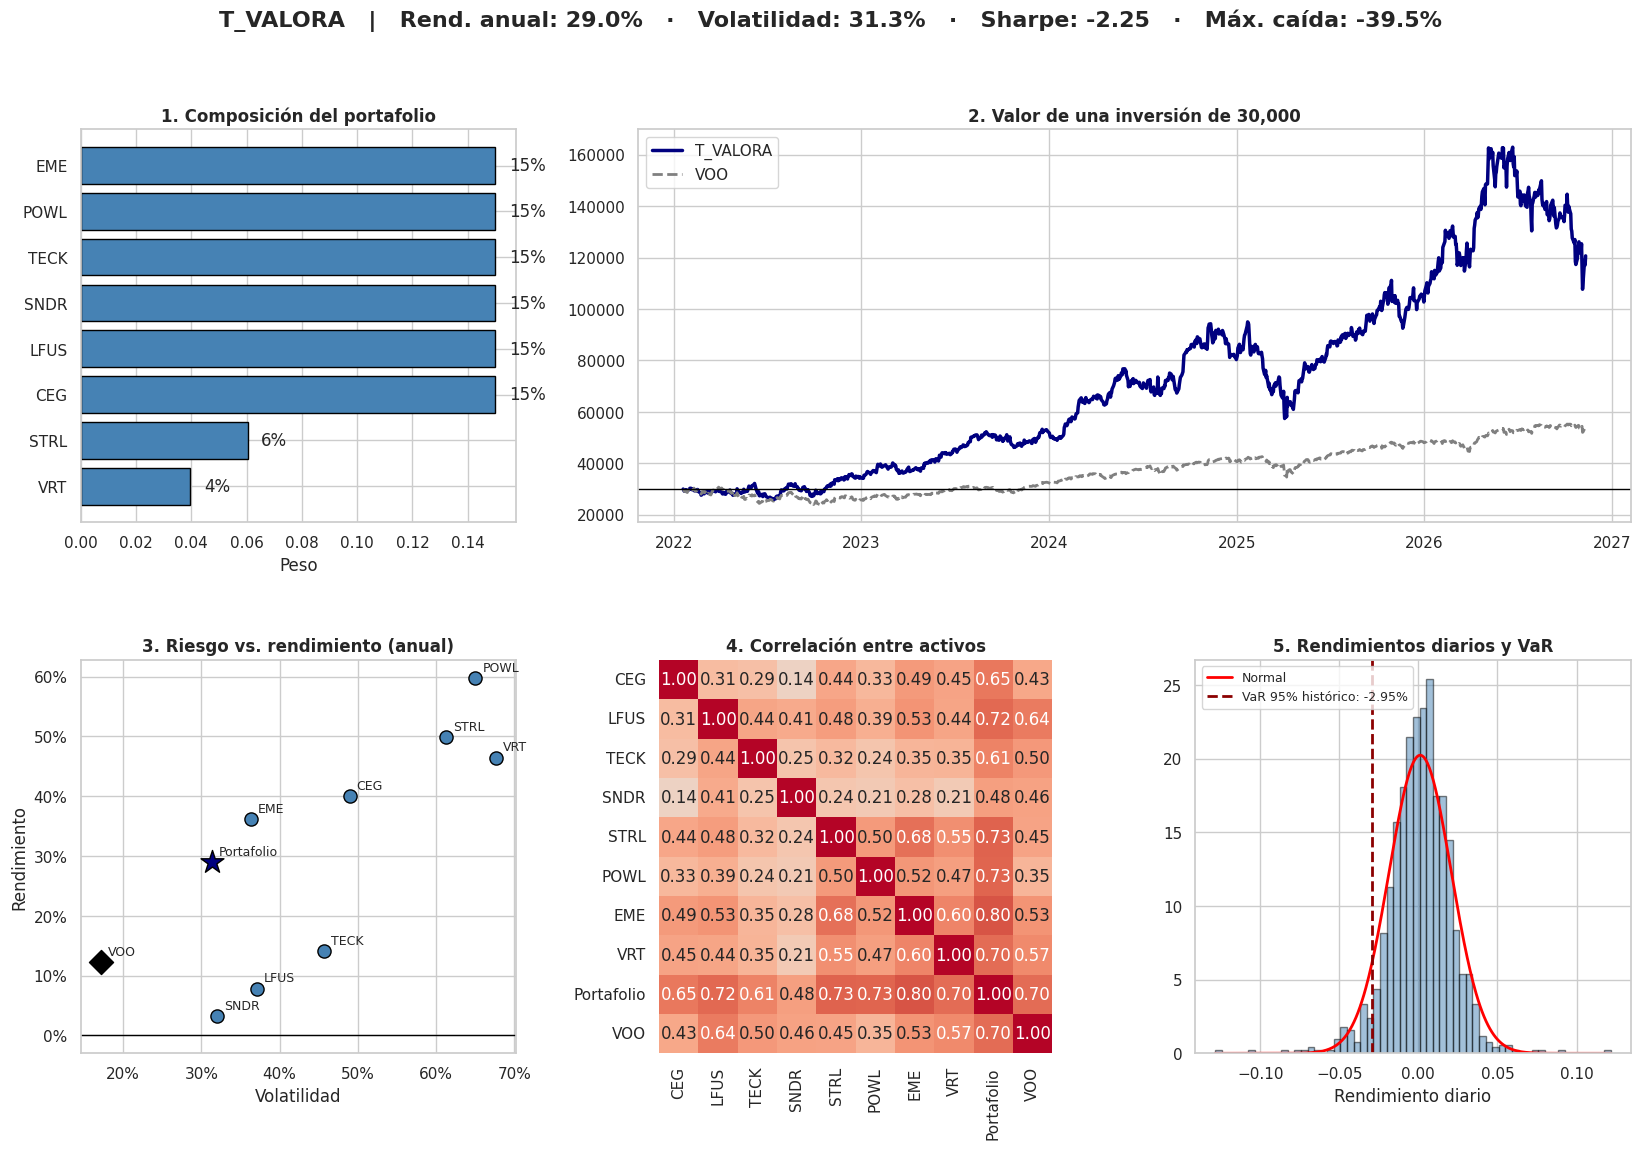

Imagen guardada como dashboard_borrador.png (panel Archivos de Colab, a la izquierda)


In [30]:
fig = plt.figure(figsize=(20, 12))
grid = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.28)

# --- Panel 1: composición -------------------------------------------------
ax1 = fig.add_subplot(grid[0, 0])
pesos_ord = pesos.sort_values()
ax1.barh(pesos_ord.index, pesos_ord.values, color="steelblue", edgecolor="black")
for i, v in enumerate(pesos_ord.values):
    ax1.text(v + 0.005, i, f"{v:.0%}", va="center")
ax1.set_title("1. Composición del portafolio", fontweight="bold")
ax1.set_xlabel("Peso")

# --- Panel 2: valor de la inversión -----------------------------------------
ax2 = fig.add_subplot(grid[0, 1:])
ax2.plot(valor_port_c.index, valor_port_c, color="navy", linewidth=2.5, label=nombre_portafolio)
ax2.plot(valor_bench_c.index, valor_bench_c, color="gray", linestyle="--", linewidth=2, label=benchmark)
ax2.axhline(monto_inicial, color="black", linewidth=1)
ax2.set_title(f"2. Valor de una inversión de {monto_inicial:,.0f}", fontweight="bold")
ax2.legend()

# --- Panel 3: riesgo–rendimiento --------------------------------------------
ax3 = fig.add_subplot(grid[1, 0])
for nombre in resumen.index:
    x, y = resumen.loc[nombre, "Volatilidad anualizada"], resumen.loc[nombre, "Rend. anualizado"]
    estilo = {"Portafolio": ("navy", "*", 300), benchmark: ("black", "D", 150)}.get(nombre, ("steelblue", "o", 90))
    ax3.scatter(x, y, color=estilo[0], marker=estilo[1], s=estilo[2], edgecolor="black", zorder=3)
    ax3.annotate(nombre, (x, y), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax3.axhline(0, color="black", linewidth=1)
ax3.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax3.set_title("3. Riesgo vs. rendimiento (anual)", fontweight="bold")
ax3.set_xlabel("Volatilidad")
ax3.set_ylabel("Rendimiento")

# --- Panel 4: correlación ----------------------------------------------------
ax4 = fig.add_subplot(grid[1, 1])
print(corr_promedio)
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, cbar=False, ax=ax4)
ax4.set_title("4. Correlación entre activos", fontweight="bold")

# --- Panel 5: distribución y VaR ---------------------------------------------
ax5 = fig.add_subplot(grid[1, 2])
ax5.hist(rend_port, bins=60, density=True, color="steelblue", alpha=0.5, edgecolor="black")
xs = np.linspace(rend_port.min(), rend_port.max(), 400)
ax5.plot(xs, norm.pdf(xs, mu_p, sigma_p), color="red", linewidth=2, label="Normal")
ax5.axvline(rend_port.quantile(0.05), color="darkred", linestyle="--", linewidth=2,
            label=f"VaR 95% histórico: {q05_emp:.2%}")
ax5.set_title("5. Rendimientos diarios y VaR", fontweight="bold")
ax5.set_xlabel("Rendimiento diario")
ax5.legend(fontsize=9)

# --- Título con los indicadores clave ---------------------------------------
f = ficha_tecnica["Portafolio"]
fig.suptitle(
    f"{nombre_portafolio}   |   Rend. anual: {f['Rendimiento anualizado']:.1%}   ·   "
    f"Volatilidad: {f['Volatilidad anualizada']:.1%}   ·   Sharpe: {f['Sharpe']:.2f}   ·   "
    f"Máx. caída: {f['Máxima caída']:.1%}",
    fontsize=16, fontweight="bold"
)

fig.savefig("dashboard_borrador.png", dpi=200, bbox_inches="tight")
plt.show()
print("Imagen guardada como dashboard_borrador.png (panel Archivos de Colab, a la izquierda)")

### ✍️ 12.2 Mejora el borrador

1. ¿El título comunica de un vistazo lo más importante? ¿Cambiarías algún indicador?
2. Falta el panel de **drawdown**. ¿Dónde lo pondrías? ¿Qué panel quitarías si solo pudieras tener cinco?
3. ¿Qué **interactividad** le agregarías en el dashboard final (filtros de fechas, selector de activo, cambio de pesos...)?

**Respuestas:**

# 13. ✍️ Del análisis al mensaje: resumen para inversionistas

Un inversionista tiene poco tiempo. Escribe el texto que acompañaría tu dashboard. **Cada afirmación debe estar respaldada por una cifra o un gráfico de este notebook.**

### 13.1 Resumen ejecutivo (máximo 5 líneas)

*Qué es el portafolio, cómo le fue frente al benchmark y cuál es su perfil de riesgo.*

**Respuesta:**

### 13.2 Tres hallazgos clave

1. **Rendimiento:**
2. **Riesgo y diversificación:**
3. **Eventos extremos:**

### 13.3 Principales riesgos

*Concentración en un sector, correlaciones altas, colas pesadas, máxima caída...*

**Respuesta:**

### 13.4 Limitaciones del análisis

*Piensa en: período de datos, rendimientos pasados frente a futuros, supuesto de normalidad, rebalanceo diario, costos de transacción, tipo de cambio...*

**Respuesta:**

### 13.5 Perfil de inversionista

*¿Para qué tipo de inversionista sería adecuado este portafolio (conservador, moderado, agresivo)? Justifica con los indicadores.*

**Respuesta:**

> ⚠️ Recuerda incluir en la presentación una nota del tipo: *"Rendimientos pasados no garantizan rendimientos futuros. Este análisis tiene fines académicos y no constituye una recomendación de inversión."*

# 14. ✅ Lista de chequeo antes de entregar

- [ ] Ejecuté **todo** el notebook de principio a fin sin errores (*Entorno de ejecución → Reiniciar y ejecutar todo*).
- [ ] No queda ningún `___` en el código.
- [ ] Respondí todas las preguntas ✍️ con **mis** resultados, no con ejemplos genéricos.
- [ ] Los gráficos tienen título, ejes con nombre y leyenda cuando corresponde.
- [ ] La ficha técnica compara el portafolio con el benchmark.
- [ ] El resumen para inversionistas usa cifras concretas y menciona limitaciones.
- [ ] Guardé `dashboard_borrador.png`.

### Criterios de evaluación sugeridos

| Criterio | Peso |
|---|---|
| Definición y justificación del portafolio (secciones 1–2) | 10% |
| Código completo y funcional (todas las secciones) | 25% |
| Calidad e interpretación de los gráficos (3–7) | 20% |
| Análisis de probabilidad, normalidad y VaR (8–10) | 20% |
| Ficha técnica y borrador del dashboard (11–12) | 10% |
| Mensaje para inversionistas (13) | 15% |

---

### 🚀 Siguiente paso: el proyecto

Con este notebook ya tienen **los datos, las cifras y los mensajes**. En el proyecto los convertirán en un dashboard interactivo y en una presentación para inversionistas.